# Projet Machine Learning — Régression linéaire

## Prédire les dépenses alimentaires à partir du revenu

Dans ce projet, nous allons utiliser un **vrai jeu de données** contenant des informations sur 235 ménages ouvriers en Belgique en 1857.

L'objectif est de prédire les **dépenses alimentaires annuelles** à partir du **revenu annuel du ménage**.

Nous utiliserons uniquement la **régression linéaire**.

### Objectifs

- charger et explorer un jeu de données réel ;
- visualiser la relation entre deux variables ;
- séparer les données en entraînement et test ;
- entraîner un modèle `LinearRegression` ;
- comprendre la droite de régression ;
- évaluer les prédictions avec MAE, RMSE et R² ;
- faire une prédiction sur une nouvelle valeur.


## Variables

Le dataset contient deux variables :

- `revenu_annuel` : revenu annuel du ménage ;
- `depenses_alimentaires_annuelles` : dépenses alimentaires annuelles.

La variable que nous voulons prédire est :

`depenses_alimentaires_annuelles`


## 1. Importer les bibliothèques

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


## 2. Charger les données

In [14]:
df = pd.read_csv("engel_regression.csv")

df.head()


,revenu_annuel,depenses_alimentaires_annuelles
0,420.157651,255.839425
1,541.411707,310.958667
2,901.157457,485.680014
3,639.080229,402.997356
4,750.875606,495.560775


In [15]:
# Votre code ici


## 3. Explorer les données

In [16]:
df.describe()


,revenu_annuel,depenses_alimentaires_annuelles
count,235.000000,235.000000
mean,982.473044,624.150111
std,519.230879,276.456997
min,377.058369,242.320202
25%,638.875788,429.688763
50%,883.984917,582.541251
75%,1163.986672,743.881432
max,4957.813024,2032.679190


## Exercice 2

À partir du tableau précédent :

1. Quel est le revenu annuel moyen ?
2. Quelle est la dépense alimentaire annuelle moyenne ?
3. Quelles sont les valeurs minimale et maximale du revenu ?


## 4. Visualiser la relation entre les variables

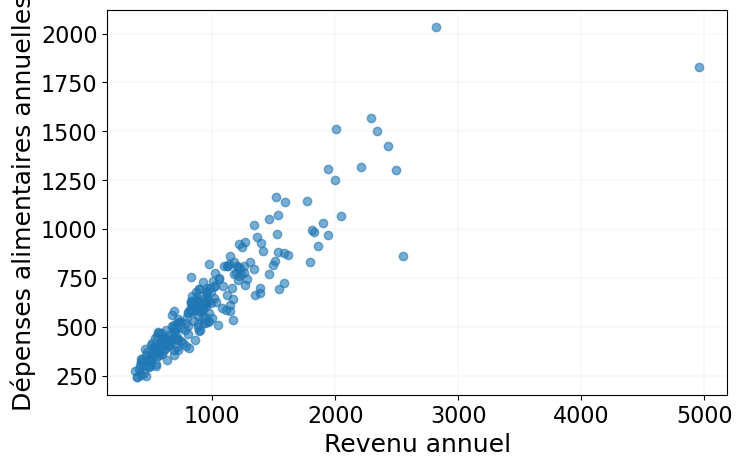

In [17]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["revenu_annuel"],
    df["depenses_alimentaires_annuelles"],
    alpha=0.6
)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.xlabel("Revenu annuel", fontsize=18)
plt.ylabel("Dépenses alimentaires annuelles", fontsize=18)
plt.grid(True, linewidth=0.1)

plt.show()


## Question

Que remarquez-vous ?

Les dépenses alimentaires semblent-elles augmenter lorsque le revenu augmente ?


## 5. Définir X et y

In [18]:
X = df[["revenu_annuel"]]
y = df["depenses_alimentaires_annuelles"]

print("X :", X.shape)
print("y :", y.shape)


X : (235, 1)
y : (235,)


Ici :

- `X` contient la variable utilisée pour faire la prédiction ;
- `y` contient la variable que nous voulons prédire.


## 6. Séparer les données en entraînement et test

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Entraînement :", X_train.shape)
print("Test :", X_test.shape)


Entraînement : (188, 1)
Test : (47, 1)


In [20]:
y_train

117     662.009562
155     830.958622
148    1250.964334
158     383.457963
232     468.000798
          ...     
106     534.761044
14      512.720058
92      821.596994
179     327.418772
102     517.919591
Name: depenses_alimentaires_annuelles, Length: 188, dtype: float64

## Question

Pourquoi faut-il garder une partie des données pour tester le modèle ?


## 7. Créer et entraîner le modèle

In [21]:
model = LinearRegression()

model.fit(X_train, y_train)


LinearRegression()

## 8. Examiner l'équation de la droite

In [22]:
model.coef_

array([0.46172701])

In [23]:
print("Coefficient :", model.coef_[0])
print("Intercept :", model.intercept_)


Coefficient : 0.4617270132870568
Intercept : 163.07569195181787


Le modèle apprend une relation de la forme :


$\hat{y} = b_0 + b_1x$


où :

- $x$ est le revenu annuel ;
- $b_0$ est l'intercept ;
- $b_1$ est le coefficient ;
- $\hat{y}$ est la dépense alimentaire prédite.


## 9. Visualiser la droite de régression

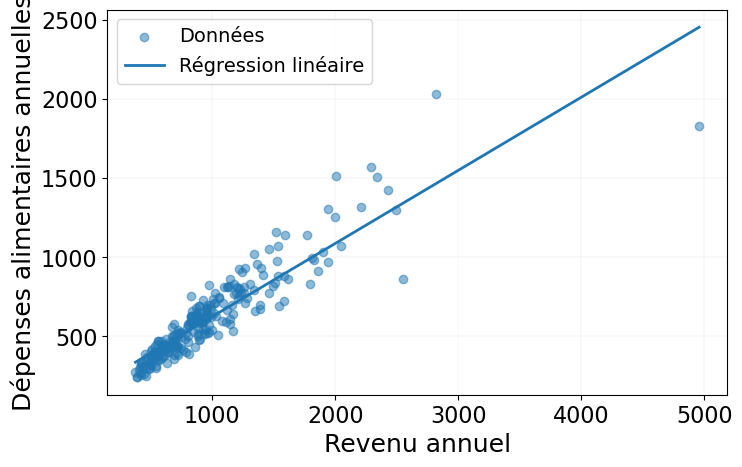

In [24]:
x_line = np.linspace(
    df["revenu_annuel"].min(),
    df["revenu_annuel"].max(),
    200
)

x_line_df = pd.DataFrame({
    "revenu_annuel": x_line
})

y_line = model.predict(x_line_df)

plt.figure(figsize=(8, 5))

plt.scatter(
    df["revenu_annuel"],
    df["depenses_alimentaires_annuelles"],
    alpha=0.5,
    label="Données"
)

plt.plot(
    x_line,
    y_line,
    linewidth=2,
    label="Régression linéaire"
)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=14)

plt.xlabel("Revenu annuel", fontsize=18)
plt.ylabel("Dépenses alimentaires annuelles", fontsize=18)
plt.grid(True, linewidth=0.1)

plt.show()


## Exercice 3

Observez la droite.

1. La droite représente-t-elle parfaitement toutes les observations ?
2. Pourquoi certains points sont-ils éloignés de la droite ?
3. Que représente la pente de la droite ?


## 10. Faire des prédictions

In [25]:
y_pred = model.predict(X_test)

y_pred[:10]


array([ 872.29766539,  492.74780284,  508.74361601,  852.15650683,
       1090.61813778,  668.85405575,  493.38138133,  780.86566924,
        393.82423448,  550.35205599])

## 11. Évaluer le modèle

In [26]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.3f}")


MAE  : 82.42
RMSE : 119.90
R²   : 0.845


### Interprétation

- **MAE** : erreur absolue moyenne ;
- **RMSE** : erreur quadratique moyenne, qui pénalise davantage les grosses erreurs ;
- **R²** : proportion de la variabilité de la cible expliquée par le modèle.


## 12. Comparer observations et prédictions

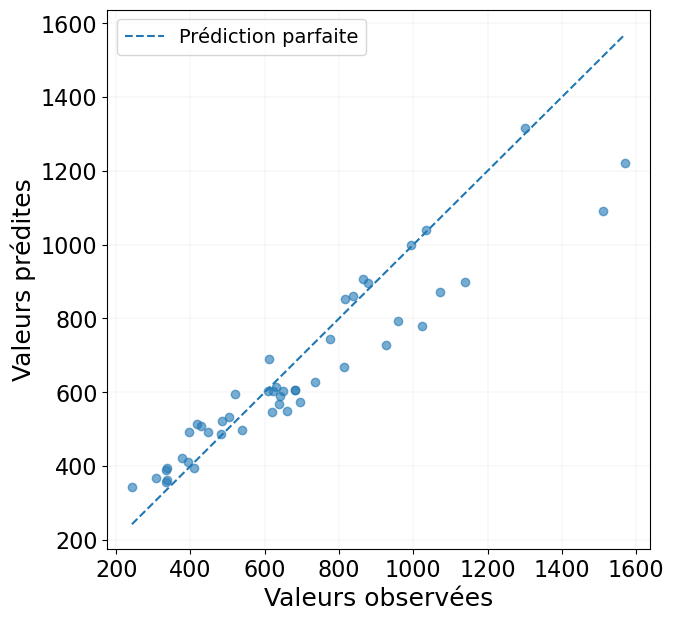

In [27]:
plt.figure(figsize=(7, 7))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.6
)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    label="Prédiction parfaite"
)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=14)

plt.xlabel("Valeurs observées", fontsize=18)
plt.ylabel("Valeurs prédites", fontsize=18)
plt.grid(True, linewidth=0.1)

plt.show()


## Exercice 4

1. Que signifie un point situé exactement sur la diagonale ?
2. Que signifie un point éloigné de la diagonale ?
3. Le modèle semble-t-il mieux fonctionner pour certaines valeurs que pour d'autres ?


## 13. Faire une nouvelle prédiction

In [28]:
nouveau_revenu = pd.DataFrame({
    "revenu_annuel": [1000]
})

prediction = model.predict(nouveau_revenu)

print(
    f"Dépenses alimentaires prédites : "
    f"{prediction[0]:.2f}"
)


Dépenses alimentaires prédites : 624.80


## Exercice 5

Modifiez la valeur du revenu et observez la prédiction.

Essayez par exemple :

- 500
- 1000
- 1500
- 2000
- 3000


## Questions de conclusion

1. Quelle est la variable explicative ?
2. Quelle est la variable cible ?
3. Pourquoi ce problème est-il une régression ?
4. Que représente le coefficient du modèle ?
5. Que représente l'intercept ?
6. Que signifie un R² proche de 1 ?
7. Pourquoi une droite ne peut-elle pas nécessairement expliquer parfaitement toutes les observations ?
